In [2]:
import fnmatch
import os
import pickle
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

sys.path.insert(0, str(Path.cwd().parent / "scripts"))   # folder containing utils.py
import utils
plt.style.use("../plotstyling.mplstyle")

In [6]:
pairs_file = "../data/earthcare_aws_file_pairs_2025-07_to_2026-06.pkl"
pattern = "*2025080521*"      # matched against the AWS file name
max_dist_km = 15.0

with open(pairs_file, "rb") as f:
    pairs = pickle.load(f)

matches = [(a, e) for a, e in pairs if fnmatch.fnmatch(os.path.basename(str(a)), pattern)]
print(f"{len(matches)} collocations match {pattern}")


1 collocations match *2025080521*


AWS:       l2_arctic_20250805212703_20250805230517_v3.nc
EarthCARE: ECA_EXBA_ACM_CAP_2B_20250805T213324Z_20250808T090956Z_06752C.h5


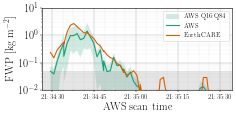

In [12]:

for aws_path, ea_path in matches:
    print("AWS:      ", Path(aws_path).name)
    print("EarthCARE:", Path(ea_path).name)

    col = utils.colocate_pair_nearest_profile(aws_path, ea_path, max_dist_km=max_dist_km)
    if col["scan"].size == 0:
        print(f"  no AWS pixels within {max_dist_km} km of EarthCARE")
        continue

    sel = np.argsort(col["scan"], kind="stable")      # in time order
    x = mdates.date2num(col["scan"][sel])

    fig, ax = plt.subplots(figsize=(6, 3))
    ax.fill_between(x, col["aws_fwp_q16"][sel], col["aws_fwp_q84"][sel],
                    color="C0", alpha=0.2, lw=0, label="AWS Q16:Q84")
    ax.plot(x, col["aws_fwp"][sel], color="C0", lw=2, label="AWS")
    ax.plot(x, col["ea_iwp"][sel], color="C1", lw=2, label="EarthCARE")

    ax.set_yscale("log")
    ax.set_ylim([1e-2, 1e1])
    ax.axhspan(1e-2, 5e-2, color="grey", alpha=0.2)
    ax.set_ylabel(r"FWP [kg m$^{-2}$]")
    ax.set_xlabel("AWS scan time")
    ax.tick_params(axis="x", labelsize=12)
    ax.xaxis.set_major_locator(mdates.SecondLocator(bysecond=range(0, 60, 15)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
    ax.minorticks_on()
    ax.grid(True, which="major", lw=0.8)
    ax.grid(True, which="minor", lw=0.3, alpha=0.5)
    ax.legend(fontsize=12)
    #ax.set_title(Path(ea_path).stem, fontsize=10)

    fig.tight_layout()

plt.savefig(f"../figures/august_match_with_gunnars.png",
            facecolor="white", bbox_inches="tight", dpi=200)

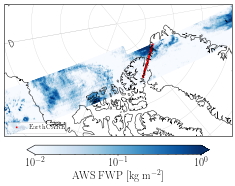

In [38]:
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean as cmc
from matplotlib.colors import LogNorm

pad_km = 300          # space around the EarthCARE track; adjust to zoom in or out

with xr.open_dataset(aws_path) as ds:
    lat = ds["latitude"].values
    lon = ds["longitude"].values
    fwp = ds["fwp_mean"].values

geo = ccrs.PlateCarree()
proj = ccrs.NorthPolarStereo(central_longitude=-100)

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={"projection": proj})

# extent: a box around the collocated track, in the map's own coordinates (metres)
track = proj.transform_points(geo, col["lon"][sel], col["lat"][sel])
pad = pad_km * 1e3
lon_min, lon_max = -180, 0      # degrees east
lat_min, lat_max = 70, 90       # degrees north
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=geo)

ax.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor="white", zorder=0)
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="white", zorder=0)
ax.coastlines(resolution="50m", color="black", linewidth=0.8, zorder=10)
ax.gridlines(draw_labels=False, linewidth=0.3)

sc = ax.scatter(lon, lat, c=fwp, s=4, ec="none",
                norm=LogNorm(vmin=1e-2, vmax=1e0), cmap="Blues",
                transform=geo, zorder=2)
ax.scatter(col["lon"][sel], col["lat"][sel], c="red", s=10, ec="none",
           transform=geo, zorder=3, label="EarthCARE")

ax.legend(loc="lower left", fontsize=12)
fig.colorbar(sc, ax=ax, orientation="horizontal", shrink=0.8, pad=0.04, extend="both",
             label=r"AWS FWP [kg m$^{-2}$]")

fig.tight_layout()
plt.savefig("../figures/august_match_with_gunnars_map.png",
            facecolor="white", bbox_inches="tight", dpi=200)